# Le testate sul piano: quanto separano le caratteristiche di stile?

Il notebook 2 ha trovato che le testate affidabili scrivono con **più ragionamento** e **meno emotività**. Qui lo
guardiamo direttamente: **un punto per testata** su un piano cartesiano, con due caratteristiche di stile sugli assi.
Se le testate poco e molto affidabili scrivono in modo diverso, le loro nuvole stanno in zone diverse del piano.

Le caratteristiche sono **4 indici**, ognuno la media di alcune misure del notebook 2 (in deviazioni standard),
scelte per significato **prima** di guardare i risultati:

| indice | che cosa misura | misure |
|---|---|---|
| **ragionamento** | quanto si argomenta e si sfuma | connettivi avversativi (*however, whereas*), concessivi (*although*), causali (*because, therefore*); cautela (*may, likely, suggests*); subordinate per frase |
| **emotività** | quanto si alza il tono | parole emotive; parole ad alta attivazione; punti esclamativi; parole in maiuscolo |
| **complessità** | quanto sono costruite le frasi | parole per frase; profondità sintattica; distanza tra parole collegate; varietà del lessico; nominalizzazioni |
| **fonti** | quanto si citano fonti e dati | attribuzioni (*said, according to*); virgolette; nomi propri e organizzazioni; numeri e date |

In [1]:
T14_DIR = "../14_DatasetRipensatoChunk"         # dataset del tentativo 14
STILE = "Results/cache/stile_articoli.csv.gz"   # misure di stile per articolo (dal notebook 2)

In [2]:
# Parameters
T14_DIR = "/home/fabio.pinelli/John/Tentativo14"


In [3]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
from sklearn.metrics import roc_auc_score

T14 = Path(T14_DIR).expanduser()
sys.path.insert(0, str(T14))
import funzioni as F

warnings.filterwarnings("ignore")
GRAFICI = Path("Results/grafici_separazione"); GRAFICI.mkdir(parents=True, exist_ok=True)
BLU, ARANCIO, GRIGIO, CHIARO, FONDO = "#2a78d6", "#eb6834", "#52514e", "#b5b3ab", "#e1e0d9"
ROSSO, BLU_SCURO = "#b02a2a", "#1c5cab"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({
    "figure.figsize": (8, 3), "figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "legend.frameon": False,
})
pd.set_option("display.width", 220)

def salva(nome):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", dpi=180, bbox_inches="tight"); plt.show()

def ellisse(ax, x, y, colore):
    """Ellisse che contiene circa metà dei punti di un gruppo (dalla loro covarianza), più il centro."""
    x, y = np.asarray(x), np.asarray(y)
    valori, vettori = np.linalg.eigh(np.cov(x, y))
    angolo = np.degrees(np.arctan2(vettori[1, 1], vettori[0, 1]))
    w, h = 2 * np.sqrt(valori[::-1] * 1.386)                 # 1,386 = quantile 50% del chi quadro con 2 gradi di libertà
    ax.add_patch(Ellipse((x.mean(), y.mean()), w, h, angle=angolo, fill=False, color=colore, lw=2))
    ax.plot(x.mean(), y.mean(), "+", color=colore, ms=12, mew=2.5)

## 1. Gli indici di ogni testata

In [4]:
# 1.1 dataset del tentativo 14 e misure di stile del notebook 2: la media per testata, poi i 4 indici
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")
st = pd.read_csv(STILE)
MISURE = [c for c in st.columns if c not in ("article_id", "domain", "distorto")]
pt = st[MISURE].groupby(st.domain).mean().reindex(t.index)
z = (pt - pt.mean()) / pt.std()                       # ogni misura in deviazioni standard (senza guardare le etichette)

INDICI = {"ragionamento": ["connettivi avversativi (‰)", "connettivi concessivi (‰)", "connettivi causali (‰)",
                           "cautela, hedge (‰)", "subordinate per frase"],
          "emotività": ["parole emotive (‰)", "parole ad alta attivazione (‰)", "punti esclamativi (‰)", "parole in maiuscolo (%)"],
          "complessità": ["parole per frase", "profondità sintattica", "distanza tra parole collegate",
                          "varietà del lessico (TTR, 300 parole)", "nominalizzazioni (%)"],
          "fonti": ["attribuzione alle fonti (‰)", "virgolette (‰)", "entità nominate (per 100 parole)", "numeri e date (per 100 parole)"]}
ind = pd.DataFrame({k: z[v].mean(axis=1) for k, v in INDICI.items()})
lab = t.label.to_numpy()
print(f"{len(t)} testate; media di ogni indice per livello (in deviazioni standard):")
ind.groupby(t.livello).mean().round(2).T

323 testate; media di ogni indice per livello (in deviazioni standard):


livello,l1,l2,l3,l4,l5
ragionamento,-0.11,-0.24,-0.05,0.20,0.27
emotività,0.30,0.10,0.08,-0.17,-0.27
complessità,-0.09,-0.05,-0.04,0.01,0.24
fonti,-0.02,0.12,0.01,-0.11,0.00


Già dalle medie: salendo da l1 a l5 il **ragionamento cresce** e l'**emotività cala**, quasi in modo regolare. La
complessità cresce soprattutto in l5; le fonti non hanno un andamento.

## 2. Quanto separa ogni indice da solo

Per ogni confronto tra due gruppi di livelli, l'**AUC** di un indice: la probabilità che una testata a caso del
gruppo affidabile abbia un valore più alto di una a caso del gruppo poco affidabile. 0,5 = nessuna separazione;
1 = separazione perfetta. Qui è scritta già "girata": 0,80 vuol dire che l'indice separa all'80%, e la colonna
accanto dice in che verso.

In [5]:
# 2.1 AUC di ogni indice, per cinque confronti (l2 contro l3 è il controllo: il confine di affidabilità)
CONFRONTI = {"l1 contro l5": ([0], [4]), "l1–l2 contro l4–l5": ([0, 1], [3, 4]), "l1 contro l4": ([0], [3]),
             "l2 contro l4": ([1], [3]), "l2 contro l3 (confine)": ([1], [2])}
righe = []
for nome, (basso, alto) in CONFRONTI.items():
    dentro = np.isin(lab, basso + alto)
    for k in INDICI:
        a = roc_auc_score(np.isin(lab[dentro], alto), ind[k][dentro])
        righe.append({"confronto": nome, "indice": k, "AUC": max(a, 1 - a),
                      "verso": "più alto nelle affidabili" if a >= 0.5 else "più basso nelle affidabili"})
auc = pd.DataFrame(righe)
auc.to_csv("Results/separazione_indici.csv", index=False)
tabella = auc.pivot(index="indice", columns="confronto", values="AUC")[list(CONFRONTI)].reindex(list(INDICI))
tabella.insert(0, "verso", auc.drop_duplicates("indice").set_index("indice").verso.reindex(list(INDICI)))
tabella.round(2)

confronto,verso,l1 contro l5,l1–l2 contro l4–l5,l1 contro l4,l2 contro l4,l2 contro l3 (confine)
indice,,,,,,
ragionamento,più alto nelle affidabili,0.70,0.69,0.63,0.68,0.59
emotività,più basso nelle affidabili,0.81,0.68,0.79,0.61,0.51
complessità,più alto nelle affidabili,0.65,0.58,0.56,0.54,0.52
fonti,più basso nelle affidabili,0.53,0.57,0.55,0.60,0.54


## 3. Due indici alla volta, sul piano

Ogni punto è una testata. In ogni riga un confronto: in rosso il gruppo poco affidabile, in blu quello affidabile, in
grigio chiaro le altre testate. Le **ellissi** contengono circa metà delle testate di ogni gruppo e la **croce** è il
loro centro: più le ellissi sono lontane, più gli indici separano.

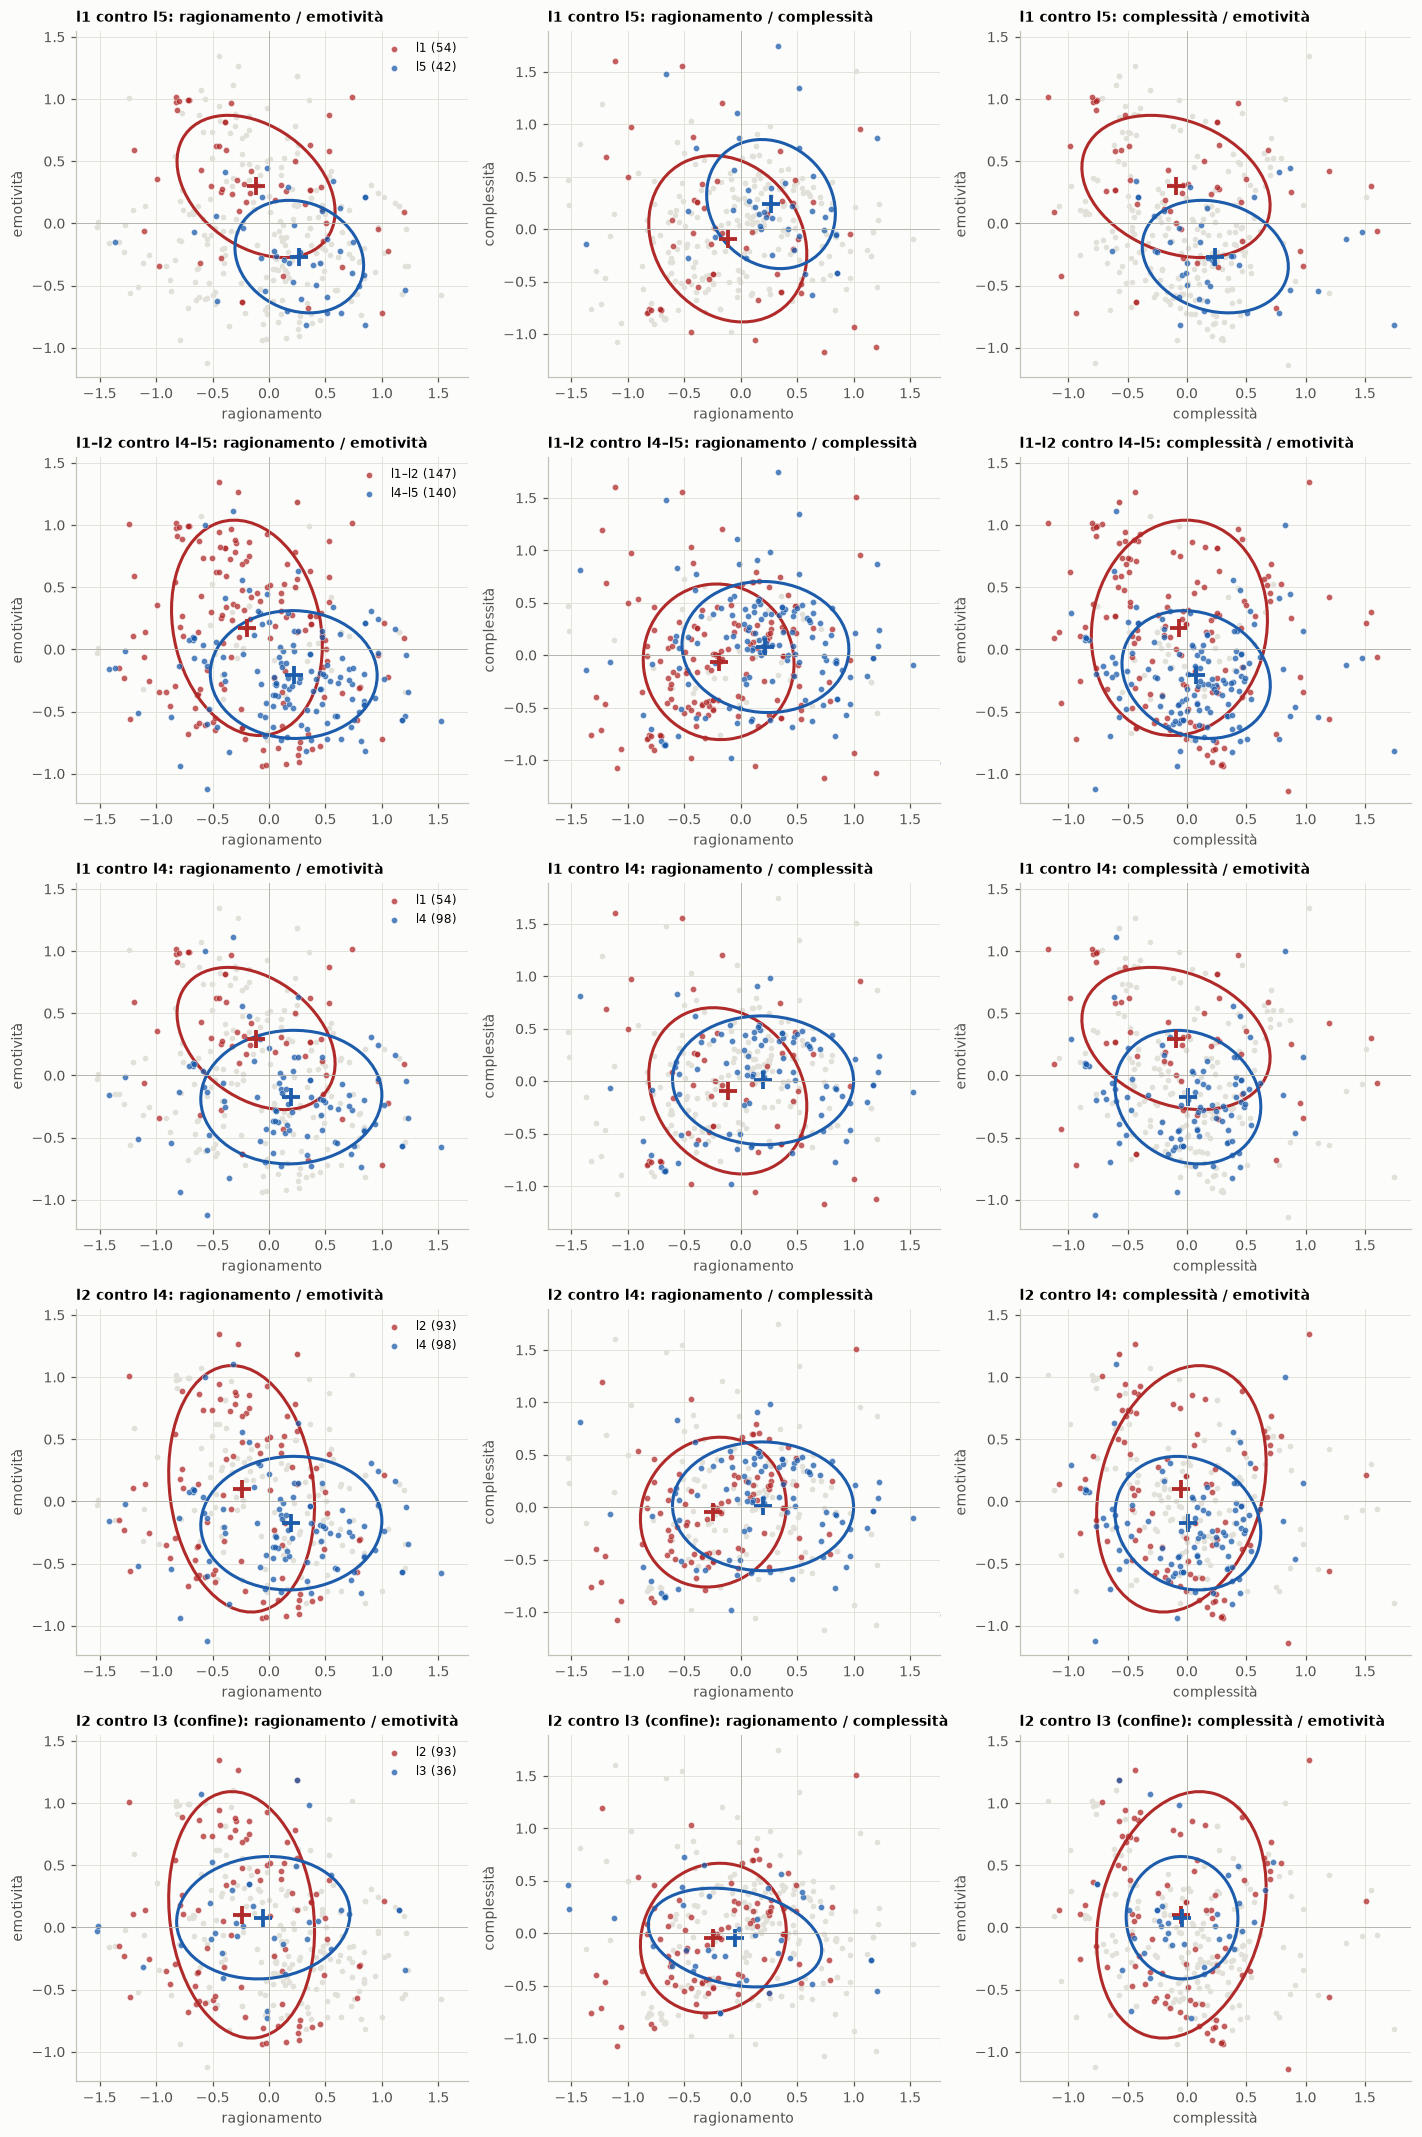

In [6]:
# 3.1 tre coppie di indici per cinque confronti
COPPIE = [("ragionamento", "emotività"), ("ragionamento", "complessità"), ("complessità", "emotività")]
lim = {k: ind[k].quantile([0.01, 0.99]).to_numpy() + [-0.3, 0.3] for k in INDICI}      # assi senza i pochi valori estremi

fig, assi = plt.subplots(len(CONFRONTI), len(COPPIE), figsize=(13, 3.9 * len(CONFRONTI)))
for r, (nome, (basso, alto)) in enumerate(CONFRONTI.items()):
    b, a_ = np.isin(lab, basso), np.isin(lab, alto)
    for c, (x, y) in enumerate(COPPIE):
        ax = assi[r, c]
        ax.scatter(ind[x][~(b | a_)], ind[y][~(b | a_)], s=7, color=FONDO)
        for m, colore, livelli in [(b, ROSSO, basso), (a_, BLU_SCURO, alto)]:
            ax.scatter(ind[x][m], ind[y][m], s=16, color=colore, alpha=0.75, edgecolor="white", linewidth=0.3,
                       label="–".join(F.LIVELLI[k] for k in livelli) + f" ({m.sum()})")
            ellisse(ax, ind[x][m], ind[y][m], colore)
        ax.set_xlim(*lim[x]); ax.set_ylim(*lim[y]); ax.set_xlabel(x); ax.set_ylabel(y)
        ax.axhline(0, color=CHIARO, lw=0.6); ax.axvline(0, color=CHIARO, lw=0.6)
        ax.set_title(f"{nome}: {x} / {y}", fontsize=9)
        if c == 0:
            ax.legend(fontsize=8, loc="upper right")
salva("3_due_indici")

Si vede il risultato principale: sul piano **ragionamento / emotività** le testate poco affidabili stanno in alto a
sinistra (meno ragionamento, più emotività), quelle affidabili in basso a destra. Le nuvole sono distinte agli estremi
ma si sovrappongono molto: è una tendenza, non un confine netto. Al confine (l2 contro l3) le ellissi coincidono.

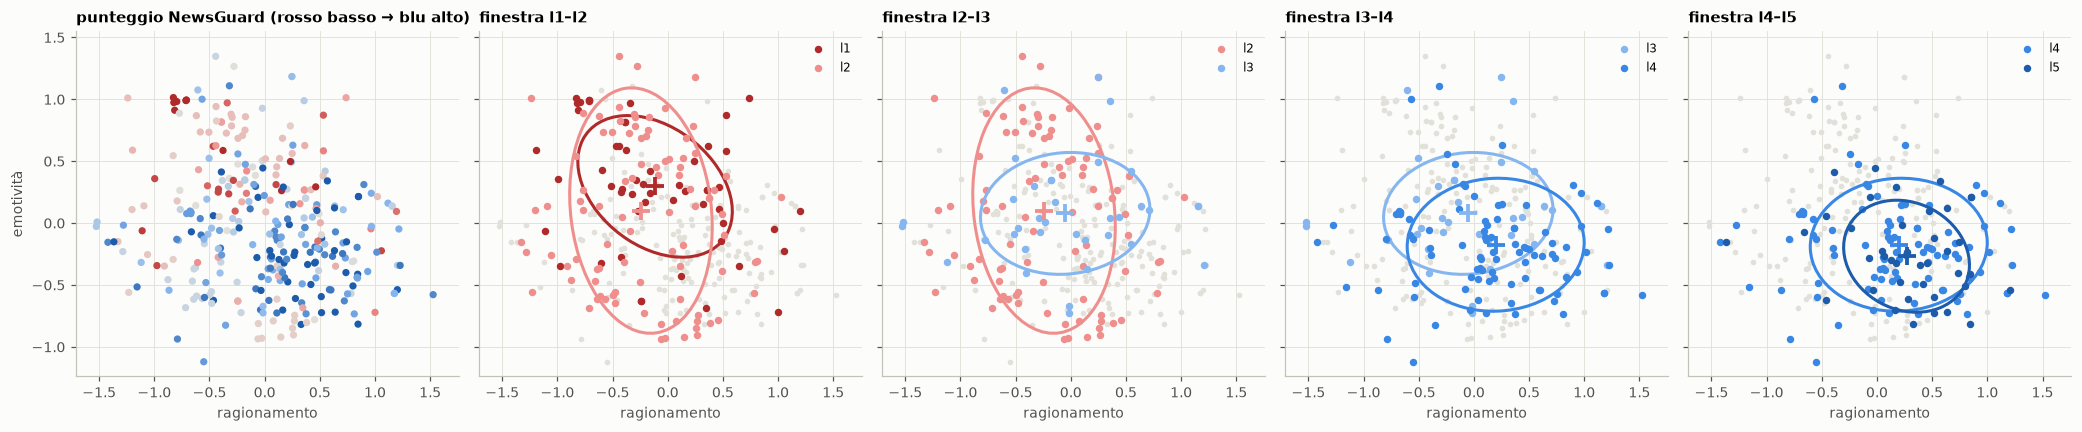

In [7]:
# 3.2 tutte le testate sul piano ragionamento / emotività: il punteggio, poi una finestra di due livelli alla volta
SCALA = LinearSegmentedColormap.from_list("punteggio", ["#b02a2a", "#ef8f8d", FONDO, "#86b6ef", "#1c5cab"])
FINESTRE = {"l1–l2": [0, 1], "l2–l3": [1, 2], "l3–l4": [2, 3], "l4–l5": [3, 4]}
fig, assi = plt.subplots(1, 5, figsize=(19, 4), sharex=True, sharey=True)
assi[0].scatter(ind["ragionamento"], ind["emotività"], c=t.score, cmap=SCALA, vmin=0, vmax=100, s=14)
assi[0].set_title("punteggio NewsGuard (rosso basso → blu alto)")
for ax, (fin, livelli) in zip(assi[1:], FINESTRE.items()):
    dentro = np.isin(lab, livelli)
    ax.scatter(ind["ragionamento"][~dentro], ind["emotività"][~dentro], s=7, color=FONDO)
    for k in livelli:
        m = lab == k
        ax.scatter(ind["ragionamento"][m], ind["emotività"][m], s=15, color=COLORE_LIVELLO[k], label=F.LIVELLI[k])
        ellisse(ax, ind["ragionamento"][m], ind["emotività"][m], COLORE_LIVELLO[k])
    ax.set_title(f"finestra {fin}"); ax.legend(fontsize=8)
for ax in assi:
    ax.set_xlabel("ragionamento"); ax.set_xlim(*lim["ragionamento"]); ax.set_ylim(*lim["emotività"])
assi[0].set_ylabel("emotività")
salva("3_finestre")

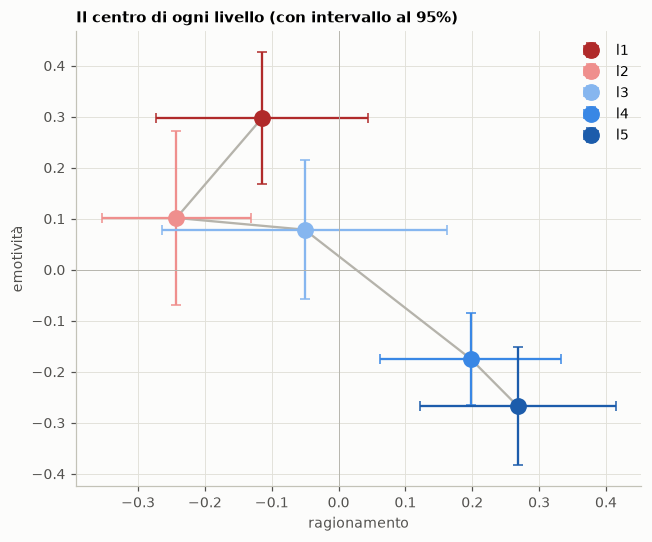

In [8]:
# 3.3 i centri dei cinque livelli sul piano: il percorso da l1 a l5
centri = ind.groupby(lab)[["ragionamento", "emotività"]].mean()
errori = ind.groupby(lab)[["ragionamento", "emotività"]].sem()
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(centri.ragionamento, centri.emotività, color=CHIARO, lw=1.5, zorder=1)
for k in range(5):
    ax.errorbar(centri.ragionamento[k], centri.emotività[k], xerr=1.96 * errori.ragionamento[k], yerr=1.96 * errori.emotività[k],
                fmt="o", color=COLORE_LIVELLO[k], ms=10, capsize=3, lw=1.5, label=F.LIVELLI[k], zorder=2)
ax.axhline(0, color=CHIARO, lw=0.6); ax.axvline(0, color=CHIARO, lw=0.6)
ax.set_xlabel("ragionamento"); ax.set_ylabel("emotività"); ax.legend()
ax.set_title("Il centro di ogni livello (con intervallo al 95%)")
salva("3_percorso")

## 4. Dentro lo stesso orientamento

Quasi tutte le testate l1 sono di destra e molte l4–l5 di sinistra: la differenza di stile potrebbe essere solo una
differenza tra destra e sinistra. Rifacciamo il piano **ragionamento / emotività** separatamente per le testate di
sinistra e per quelle di destra (l1–l2 contro l4–l5).

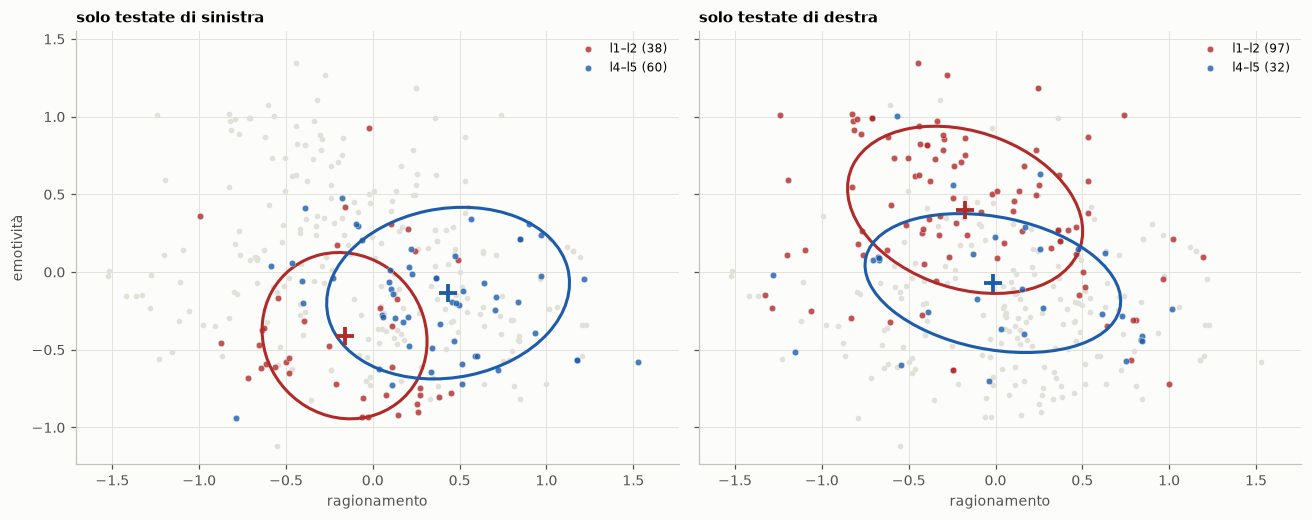

orientamento,destra,sinistra
indice,,
emotività,0.80 (più basso nelle affidabili),0.70 (più alto nelle affidabili)
ragionamento,0.58 (più alto nelle affidabili),0.80 (più alto nelle affidabili)


In [9]:
# 4.1 sinistra e destra
basso, alto = [0, 1], [3, 4]
fig, assi = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
righe = []
for ax, (o, nome) in zip(assi, [("Left", "sinistra"), ("Right", "destra")]):
    dentro = (t.orientamento == o).to_numpy()
    b, a_ = dentro & np.isin(lab, basso), dentro & np.isin(lab, alto)
    ax.scatter(ind.ragionamento[~(b | a_)], ind.emotività[~(b | a_)], s=7, color=FONDO)
    for m, colore, livelli in [(b, ROSSO, basso), (a_, BLU_SCURO, alto)]:
        ax.scatter(ind.ragionamento[m], ind.emotività[m], s=18, color=colore, alpha=0.8, edgecolor="white", linewidth=0.3,
                   label="–".join(F.LIVELLI[k] for k in livelli) + f" ({m.sum()})")
        ellisse(ax, ind.ragionamento[m], ind.emotività[m], colore)
    for k in ["ragionamento", "emotività"]:
        a = roc_auc_score(np.isin(lab[b | a_], alto), ind[k][b | a_])
        righe.append({"orientamento": nome, "indice": k,
                      "AUC": f"{max(a, 1 - a):.2f} ({'più alto' if a >= 0.5 else 'più basso'} nelle affidabili)"})
    ax.set_title(f"solo testate di {nome}"); ax.legend(fontsize=8)
    ax.set_xlabel("ragionamento"); ax.set_xlim(*lim["ragionamento"]); ax.set_ylim(*lim["emotività"])
assi[0].set_ylabel("emotività")
salva("4_per_orientamento")
pd.DataFrame(righe).pivot(index="indice", columns="orientamento", values="AUC")

Qui si vede una cosa che le medie nascondevano: **lo stile delle testate poco affidabili non è lo stesso a destra e a
sinistra**.
- **A sinistra** separa il **ragionamento** (AUC 0,80): le testate poco affidabili argomentano meno. L'emotività va al
  contrario: le testate di sinistra affidabili hanno un tono *più* acceso di quelle poco affidabili.
- **A destra** separa l'**emotività** (AUC 0,80): le testate poco affidabili alzano molto il tono. Il ragionamento
  separa poco (0,58).

Il calo di emotività da l1 a l5 visto sopra viene quindi soprattutto dalla destra, dove stanno quasi tutte le l1.

## 5. Le due misure più concrete

Gli indici sono medie; ecco le due misure singole più forti del notebook 2, nelle loro unità: **connettivi
avversativi** (*however, whereas, nevertheless, but*) e **parole emotive**, ogni 1000 parole.

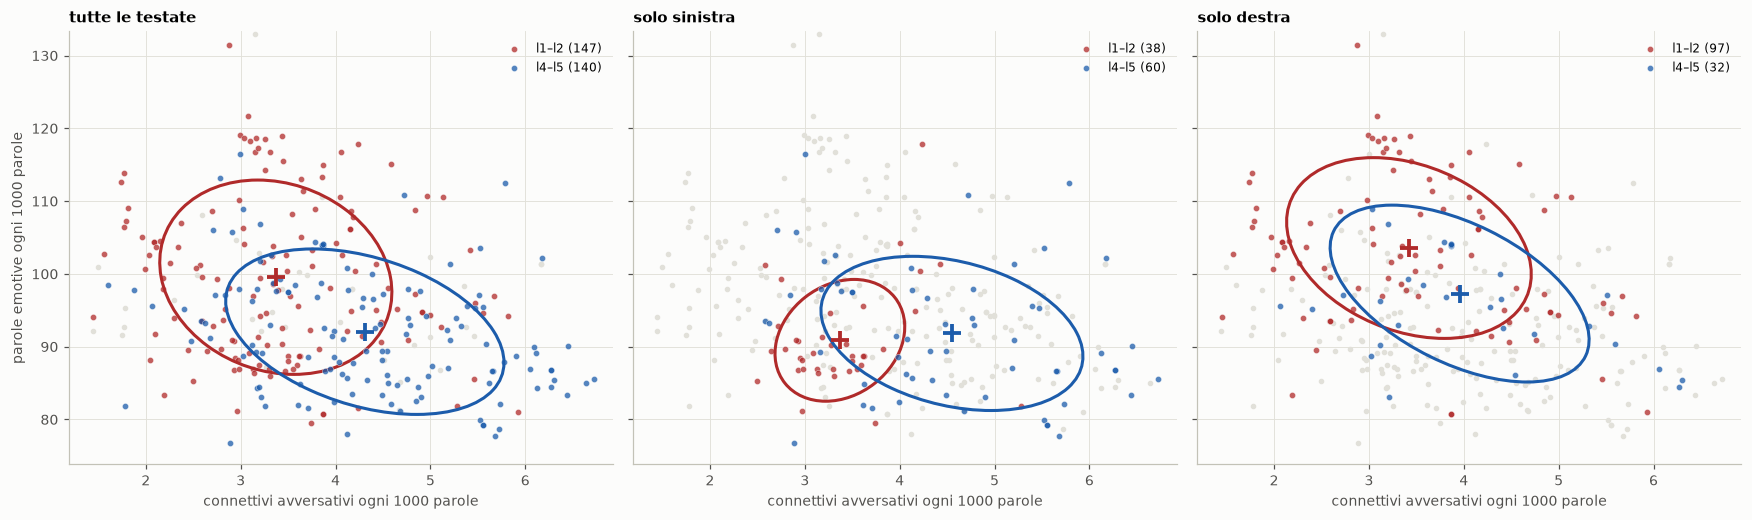

In [10]:
# 5.1 connettivi avversativi e parole emotive, l1–l2 contro l4–l5, in tutto il dataset e per orientamento
x, y = "connettivi avversativi (‰)", "parole emotive (‰)"
lx, ly = pt[x].quantile([0.01, 0.99]).to_numpy(), pt[y].quantile([0.01, 0.99]).to_numpy()
fig, assi = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, (filtro, nome) in zip(assi, [(None, "tutte le testate"), ("Left", "solo sinistra"), ("Right", "solo destra")]):
    dentro = np.ones(len(t), bool) if filtro is None else (t.orientamento == filtro).to_numpy()
    b, a_ = dentro & np.isin(lab, [0, 1]), dentro & np.isin(lab, [3, 4])
    ax.scatter(pt[x][~(b | a_)], pt[y][~(b | a_)], s=7, color=FONDO)
    for m, colore, etichetta in [(b, ROSSO, "l1–l2"), (a_, BLU_SCURO, "l4–l5")]:
        ax.scatter(pt[x][m], pt[y][m], s=16, color=colore, alpha=0.75, edgecolor="white", linewidth=0.3, label=f"{etichetta} ({m.sum()})")
        ellisse(ax, pt[x][m], pt[y][m], colore)
    ax.set_xlim(lx[0] * 0.9, lx[1] * 1.05); ax.set_ylim(ly[0] * 0.95, ly[1] * 1.03)
    ax.set_xlabel("connettivi avversativi ogni 1000 parole"); ax.set_title(nome); ax.legend(fontsize=8)
assi[0].set_ylabel("parole emotive ogni 1000 parole")
salva("5_misure_concrete")

## 6. In breve

- Sul piano **ragionamento / emotività** le testate affidabili stanno in una zona diversa: più ragionamento
  (*however, although, may*), meno emotività. Il percorso dei centri da l1 a l5 è quasi regolare.
- Agli estremi si vede bene: l'emotività da sola separa l1 da l5 all'81%, il ragionamento al 70%. Ma le nuvole si
  sovrappongono: è una **tendenza dello stile**, non un confine netto.
- Al confine di affidabilità (**l2 contro l3**) gli indici quasi non separano (al massimo 0,59).
- **Due stili diversi di inaffidabilità**:
  - a destra le testate poco affidabili sono **più emotive** (AUC 0,80);
  - a sinistra **ragionano meno** (AUC 0,80).

  Lo stile conta anche dentro lo stesso schieramento, ma non nello stesso modo.